# MSH 3-T-junction array: tensor networks vs exact diagonalization

Compares the two implementations of the 3-T-junction array, number by number:

| Files | Written by | Method |
|---|---|---|
| `msh_array_ldos_tn.csv` | `msh_tjunctions_tn.ipynb` (Julia, TensorBinding), section 5 | DMRG subgap states |
| `msh_gate_density_tdvp_{Z,X}.csv`, `msh_gate_dQ_tdvp_{Z,X}.csv`, `msh_tjunctions_tn_gates.csv` | `msh_tjunctions_tn.ipynb`, sections 6 and 8 | MPS/TDVP evolution with the MPO |
| `tjunctions_python_ed_data/*.npz` | `tjunctions_python_ed.ipynb` (Python, kwant) | exact diagonalization; full BdG basis evolved with the Gauss–Legendre step |

The CSVs are committed; run `tjunctions_python_ed.ipynb` first, in this directory, to write the `.npz` files. This notebook only loads the
files and compares them, so it runs in seconds.

Each row prints max |Julia − Python| against a tolerance set by the tensor-network method: the DMRG error for the LDOS and the zero modes,
the TDVP error (`maxdim = 64`, $dt = 0.1$) for everything time dependent. The X gate is the run with `rot_Tx = 400`. $\delta n(x, t) = n_1 - n_0$ is
taken on the horizontal chain ($y = 0$, $x = -48 \dots 47$), at the same snapshots in both codes (every 5 time units during the gate, every 1
during the fusion); $\Delta Q(t)$ is summed over all sites.

**Contents**
1. Subgap LDOS
2. MPS/TDVP: δn(x, t) and ΔQ(t)
3. Leakage and fusion quantities
4. Cost and scaling
5. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

PY_DIR = "tjunctions_python_ed_data"       # written by tjunctions_python_ed.ipynb

rows = []   # (name, max |Julia − Python|, tolerance)
def check(name, a, b, tol):
    d = float(np.max(np.abs(np.asarray(a) - np.asarray(b))))
    rows.append((name, d, tol))
    print(f"{name:<52s} {d:9.1e}  (tol {tol:.0e})  {'✓' if d <= tol else '✗'}")

def read_csv(name):
    return np.loadtxt(name, delimiter=",", skiprows=1)

def tn_density(name):
    """(t, x) table of a δn CSV (columns t, x, dn; x fastest)."""
    d = read_csv(name)
    ts, xs = np.unique(d[:, 0]), np.unique(d[:, 1])
    return ts, xs, d[:, 2].reshape(ts.size, xs.size)

## 1. Subgap LDOS

Total (particle + hole, spin-summed) LDOS $A(\mathbf r, \omega)$ of the initial setup, Gaussian width 0.01, $|\omega| \le 0.2$, on all 144 sites.
Julia uses the six lowest-|E| states from penalized DMRG (Rayleigh–Ritz in $H$); Python uses every eigenstate of the dense matrix. Inside the
window only those six states contribute, so the difference is the DMRG error.

**Plot.** $A(x, \omega = 0)$ along the horizontal chain, and $A(\omega)$ at the site with the largest zero-energy weight.

LDOS A(r, ω), DMRG (6 states) vs dense                 3.9e-04  (tol 1e-03)  ✓


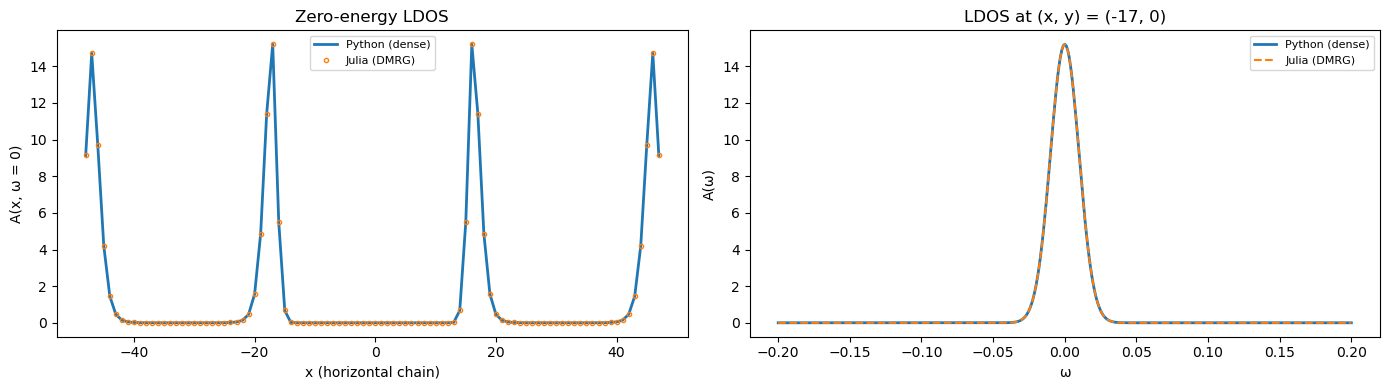

In [2]:
py_l = np.load(os.path.join(PY_DIR, "array_ldos_kwant.npz"))
x, y, om, A_py = py_l["x"], py_l["y"], py_l["omega"], py_l["A"]          # A: (site, ω)
d = read_csv("msh_array_ldos_tn.csv")
tn_map = {(int(r[0]), int(r[1]), round(r[2], 6)): r[3] for r in d}
A_tn = np.array([[tn_map[(int(x[i]), int(y[i]), round(w, 6))] for w in om] for i in range(x.size)])
check("LDOS A(r, ω), DMRG (6 states) vs dense", A_tn, A_py, 1e-3)

j0 = np.argmin(np.abs(om)); h = np.where(y == 0)[0]; h = h[np.argsort(x[h])]; i_max = np.argmax(A_py[:, j0])
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(x[h], A_py[h, j0], lw=2, label="Python (dense)")
ax[0].plot(x[h], A_tn[h, j0], "o", ms=3, mfc="none", label="Julia (DMRG)")
ax[0].set(xlabel="x (horizontal chain)", ylabel="A(x, ω = 0)", title="Zero-energy LDOS"); ax[0].legend(fontsize=8)
ax[1].plot(om, A_py[i_max], lw=2, label="Python (dense)")
ax[1].plot(om, A_tn[i_max], "--", lw=1.5, label="Julia (DMRG)")
ax[1].set(xlabel="ω", ylabel="A(ω)", title=f"LDOS at (x, y) = ({x[i_max]}, {y[i_max]})"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 2. MPS/TDVP: δn(x, t) and ΔQ(t)

The TDVP evolution of $\psi_A$, $\psi_B$ (2-site TDVP on the MPO, `maxdim = 64`) over the full gate + fusion protocol, against the Python
evolution of the full basis. The two time integrators differ: TDVP freezes $H$ at the midpoint of each step (2nd order, $dt = 0.1$), the Python
Gauss–Legendre step is 4th order ($dt = 0.25$) and converged. The midpoint rule at $dt = 0.1$ has a time-step error of a few $10^{-5}$ in the state
(measured against a converged reference), which accumulates over the long X protocol, so the tolerance for these rows is $10^{-4}$; at the end of
each protocol the two agree to $\sim 10^{-7}$ (section 3).

**Plots.** $\log_{10}|\delta n_{\rm TDVP} - \delta n_{\rm Python}|$ over the full protocol (dashed: end of the first exchange and of the gate);
$\Delta Q(t)$ during the fusion (TDVP markers on the Python curves) and $|\Delta Q_{\rm TDVP} - \Delta Q_{\rm Python}|$ over the full protocol.

TDVP δn(x, t), Z gate + fusion                         7.9e-06  (tol 1e-04)  ✓
TDVP ΔQ(t), Z gate + fusion                            8.0e-06  (tol 1e-04)  ✓
TDVP δn(x, t), X gate + fusion                         2.3e-05  (tol 1e-04)  ✓
TDVP ΔQ(t), X gate + fusion                            2.6e-05  (tol 1e-04)  ✓


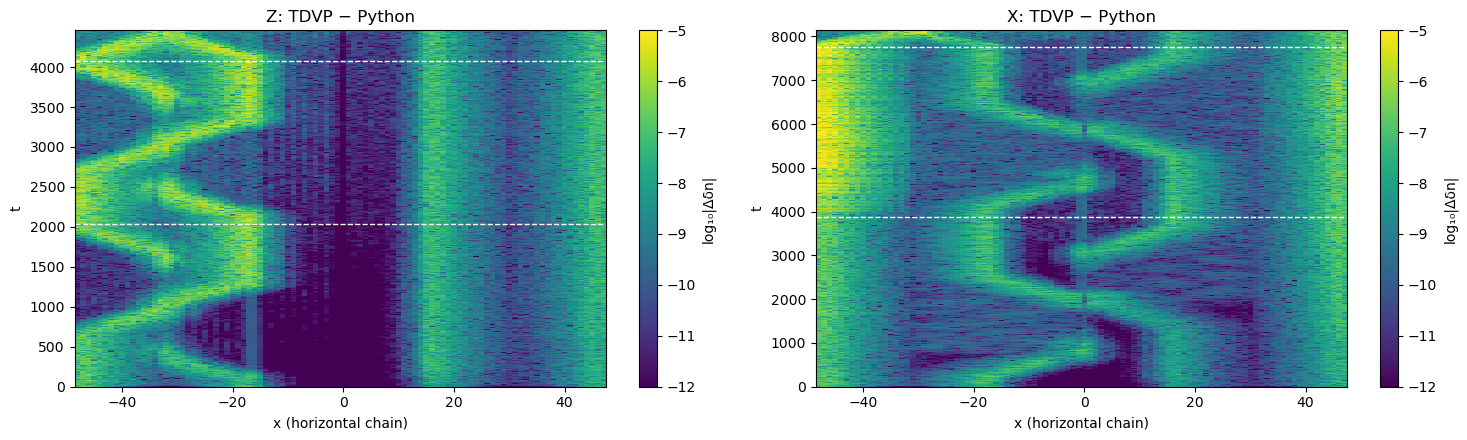

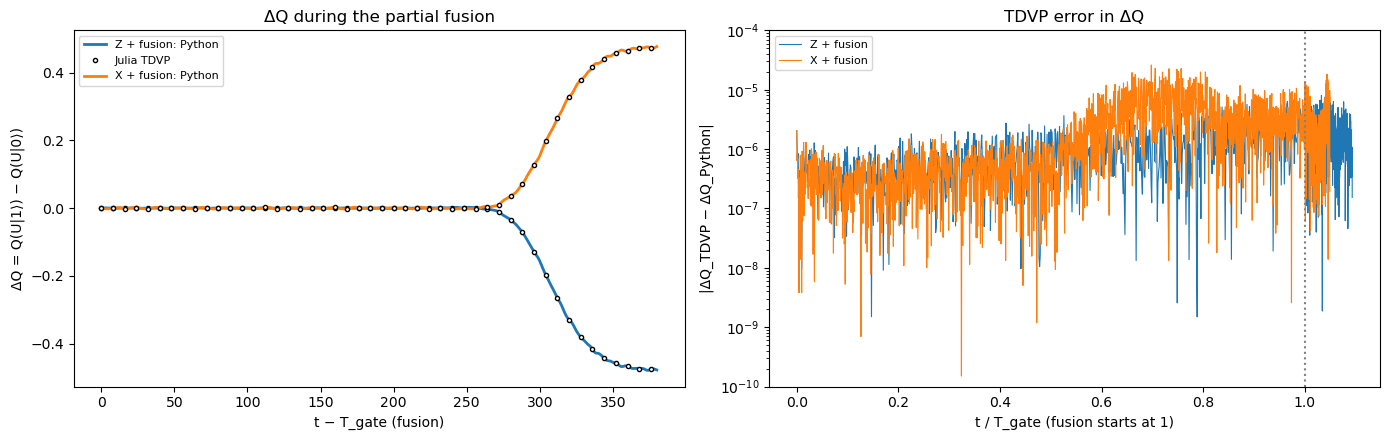

In [3]:
dens = {}
for gate, key in (("Z", "Z"), ("X", "X400")):
    ts, xs_, D_tdvp = tn_density(f"msh_gate_density_tdvp_{gate}.csv")
    dq = read_csv(f"msh_gate_dQ_tdvp_{gate}.csv")
    py = np.load(os.path.join(PY_DIR, f"gate_density_kwant_{key}.npz"))
    assert np.allclose(ts, py["ts"]) and np.allclose(dq[:, 0], py["ts"]) and np.array_equal(xs_, py["x"]), "snapshots differ"
    dens[gate] = dict(ts=ts, x=xs_, Tg=float(py["Tg"]), D_tdvp=D_tdvp, D_py=py["D"], dQ_tdvp=dq[:, 1], dQ_py=py["dQ"])
    check(f"TDVP δn(x, t), {gate} gate + fusion", D_tdvp, py["D"], 1e-4)
    check(f"TDVP ΔQ(t), {gate} gate + fusion", dq[:, 1], py["dQ"], 1e-4)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, (gate, r) in zip(ax, dens.items()):
    im = a.pcolormesh(r["x"], r["ts"], np.log10(np.maximum(np.abs(r["D_tdvp"] - r["D_py"]), 1e-16)),
                      cmap="viridis", vmin=-12, vmax=-5, shading="nearest", rasterized=True)
    for yl in (r["Tg"] / 2, r["Tg"]):
        a.axhline(yl, color="white", ls="--", lw=1)
    a.set(xlabel="x (horizontal chain)", ylabel="t", title=f"{gate}: TDVP − Python")
    fig.colorbar(im, ax=a, label="log₁₀|Δδn|")
fig.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for c, (gate, r) in enumerate(dens.items()):
    f = r["ts"] >= r["Tg"] - 1e-6
    ax[0].plot(r["ts"][f] - r["Tg"], r["dQ_py"][f], lw=2, color=f"C{c}", label=f"{gate} + fusion: Python")
    ax[0].plot((r["ts"][f] - r["Tg"])[::8], r["dQ_tdvp"][f][::8], "o", ms=3, mfc="white", mec="k",
               label="Julia TDVP" if c == 0 else None)
    ax[1].semilogy(r["ts"] / r["Tg"], np.maximum(np.abs(r["dQ_tdvp"] - r["dQ_py"]), 1e-16), lw=0.8, color=f"C{c}",
                   label=f"{gate} + fusion")
ax[0].set(xlabel="t − T_gate (fusion)", ylabel="ΔQ = Q(U|1⟩) − Q(U|0⟩)", title="ΔQ during the partial fusion"); ax[0].legend(fontsize=8)
ax[1].axvline(1.0, color="gray", ls=":")
ax[1].set(xlabel="t / T_gate (fusion starts at 1)", ylabel="|ΔQ_TDVP − ΔQ_Python|", ylim=(1e-10, 1e-4),
          title="TDVP error in ΔQ"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 3. Leakage and fusion quantities

After each gate: the leakage of each mode $\psi_A$, $\psi_B$ out of the initial zero-mode subspace. After the fusion: $\Delta Q$ for Z, X and no gate,
the leakage of $\psi_A$ out of the four lowest states of the final $H$, and $E_A$ and the adiabatic $\Delta Q$ of pair A at the end of the fusion.
Julia: TDVP and DMRG (`msh_tjunctions_tn_gates.csv`); Python: exact evolution of the full basis and diagonalization (`gates_kwant.npz`).

In [4]:
tn_g = {k: float(v) for k, v in np.genfromtxt("msh_tjunctions_tn_gates.csv", delimiter=",", names=True, dtype=None, encoding=None)}
py_g = {k: float(v) for k, v in np.load(os.path.join(PY_DIR, "gates_kwant.npz")).items()}
tols = dict(fus_E_A=1e-6, fus_dQad_A=1e-6)
labels = dict(Z_leak_A="Z: leak ψ_A", Z_leak_B="Z: leak ψ_B", X_leak_A="X: leak ψ_A", X_leak_B="X: leak ψ_B",
              Z_fus_dQ="fusion ΔQ after Z", X_fus_dQ="fusion ΔQ after X", F_fus_dQ="fusion ΔQ, no gate",
              Z_fus_leak_A="fusion leak ψ_A after Z", X_fus_leak_A="fusion leak ψ_A after X", F_fus_leak_A="fusion leak ψ_A, no gate",
              fus_dQad_A="adiabatic ΔQ of pair A (end of fusion)", fus_E_A="E_A (end of fusion)")
print(f"{'':52s} {'Julia (TN)':>12s} {'Python':>12s}")
for k, lbl in labels.items():
    print(f"{lbl:<52s} {tn_g[k]:+12.6g} {py_g[k]:+12.6g}")
print()
for k, lbl in labels.items():
    check(lbl, tn_g[k], py_g[k], tols.get(k, 1e-5))

                                                       Julia (TN)       Python
Z: leak ψ_A                                          +1.99193e-06 +1.99727e-06
Z: leak ψ_B                                          +2.07467e-11 -1.33227e-15
X: leak ψ_A                                          +3.41817e-05 +3.41631e-05
X: leak ψ_B                                          +3.48854e-05 +3.48691e-05
fusion ΔQ after Z                                       -0.477717    -0.477717
fusion ΔQ after X                                       +0.477004    +0.477004
fusion ΔQ, no gate                                      -0.477372    -0.477373
fusion leak ψ_A after Z                               +3.6929e-05  +3.6963e-05
fusion leak ψ_A after X                              +8.07556e-05  +8.0751e-05
fusion leak ψ_A, no gate                             +3.77714e-05 +3.77783e-05
adiabatic ΔQ of pair A (end of fusion)                  -0.476854    -0.476854
E_A (end of fusion)                                 

## 4. Cost and scaling

The two routes evolve different things: Julia evolves the two zero-mode fermions $\psi_A$, $\psi_B$ as MPS (2-site TDVP, $dt = 0.1$, one task per
mode); Python evolves the full $4N \times 4N$ BdG basis (sparse Gauss–Legendre step, $dt = 0.25$), from which it reads the charge density of the
logical states. Both run every evolution on one thread (Julia: BLAS on one thread; Python: `OMP_NUM_THREADS = 1`, one thread for the sparse
solve); in Julia the six evolutions ran at the same time on six threads, which slows each one a little (shared memory bandwidth).

**Measured runs** (144 sites, $D = 576$). Time for each protocol: the sum of the two TDVP evolutions in Julia, the full-basis evolution in Python.
The zero modes: DMRG (penalized, six states, refinement) against one full diagonalization.

**Scaling.** Time per unit of simulated time (the two methods use different steps) for arms of 16, 32 and 64 sites, from the benchmarks at the end
of the two notebooks (Julia: one TDVP step of each mode with bond dimension 24 on a random MPS; Python: one step of the full basis). Memory:
MPS entries for the two modes against the evolved full basis ($D^2$ entries) and one dense vector per mode ($D$).

run                        TDVP steps       time  full-basis steps       time   ratio
Z gate + fusion                 44600   144.7 min             17840    10.4 min   13.9×
X (rot_Tx = 400) + fusion       81400   275.4 min             32560    19.4 min   14.2×
fusion only                      3800    14.6 min              1520     0.9 min   16.3×
zero modes                                 320 s                       0.08 s   (DMRG + refinement vs one eigh)

 sites      D  TDVP (s per unit t)  full basis (s per unit t)     eigh  MPS entries  full basis D²
   144    576                 1.87                       0.10    0.08s         9690         331776
   288   1152                 2.31                       0.63    0.54s        11994        1327104
   576   2304                 4.95                       4.38    5.65s        14298        5308416

local power law, cost ∝ sites^p: TDVP p = 0.70, full-basis evolution p = 2.74


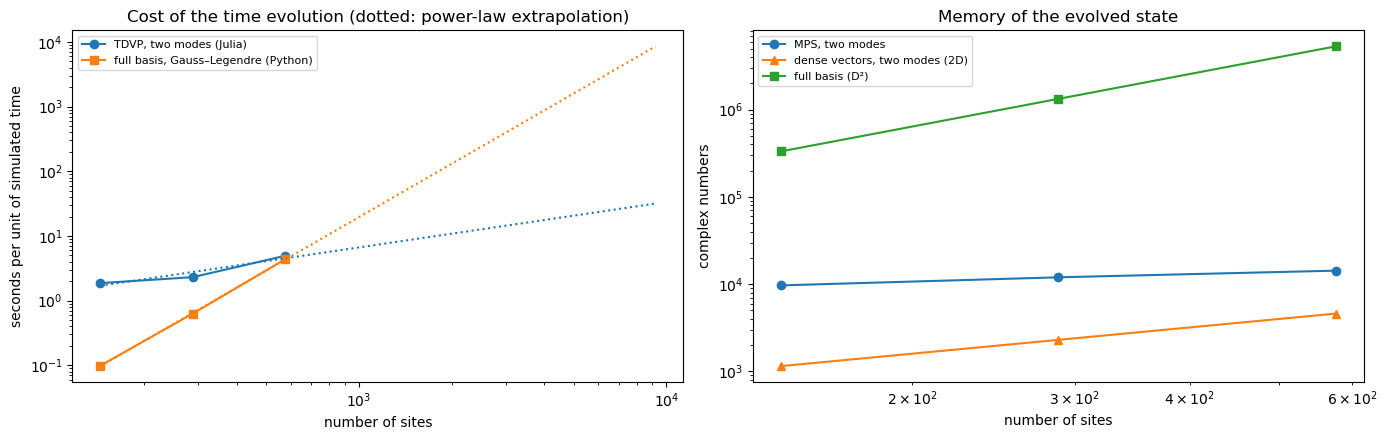

In [5]:
tt = {k: float(v) for k, v in np.genfromtxt("msh_tjunctions_tn_timing.csv", delimiter=",", names=True, dtype=None, encoding=None)}
pt = {k: np.asarray(v) for k, v in np.load(os.path.join(PY_DIR, "timing_kwant.npz")).items()}
dt_py = float(pt["dt"]); dt_tn = 0.1
print(f"{'run':26s} {'TDVP steps':>10s} {'time':>10s} {'full-basis steps':>17s} {'time':>10s} {'ratio':>7s}")
for kind, key in (("Z", "Z"), ("X", "X400"), ("F", "F")):
    t_tn = tt[f"tdvp_{kind}_A"] + tt[f"tdvp_{kind}_B"]
    t_py = float(pt[f"time_{key}_fusion"]) + (float(pt[f"time_{key}_gate"]) if f"time_{key}_gate" in pt else 0.0)
    n_py = int(pt[f"steps_{key}_fusion"]) + (int(pt[f"steps_{key}_gate"]) if f"steps_{key}_gate" in pt else 0)
    lbl = {"Z": "Z gate + fusion", "X": "X (rot_Tx = 400) + fusion", "F": "fusion only"}[kind]
    print(f"{lbl:26s} {int(tt[f'steps_{kind}']):10d} {t_tn / 60:7.1f} min {n_py:17d} {t_py / 60:7.1f} min {t_tn / t_py:6.1f}×")
print(f"{'zero modes':26s} {'':10s} {(tt['dmrg_ldos'] + tt['dmrg_mzm']):8.0f} s {'':17s} {float(pt['eigh']):8.2f} s   (DMRG + refinement vs one eigh)")

sites = np.array([tt[f"bench_sites_L{L}"] for L in (4, 5, 6)])
assert np.array_equal(sites, pt["bench_sites"])
c_tn = 2 * np.array([tt[f"bench_step_L{L}"] for L in (4, 5, 6)]) / dt_tn      # both modes, per unit of time
c_py = pt["bench_step"] / dt_py                                               # full basis, per unit of time
t_eigh = pt["bench_eigh"]
mps = 2 * np.array([tt[f"bench_mps_size_L{L}"] for L in (4, 5, 6)])
p_tn = np.polyfit(np.log(sites), np.log(c_tn), 1)[0]; p_py = np.polyfit(np.log(sites), np.log(c_py), 1)[0]
print(f"\n{'sites':>6s} {'D':>6s} {'TDVP (s per unit t)':>20s} {'full basis (s per unit t)':>26s} {'eigh':>8s} {'MPS entries':>12s} {'full basis D²':>14s}")
for i in range(3):
    D = 4 * int(sites[i])
    print(f"{int(sites[i]):6d} {D:6d} {c_tn[i]:20.2f} {c_py[i]:26.2f} {t_eigh[i]:7.2f}s {int(mps[i]):12d} {D * D:14d}")
print(f"\nlocal power law, cost ∝ sites^p: TDVP p = {p_tn:.2f}, full-basis evolution p = {p_py:.2f}")

ns = np.geomspace(sites[0], 16 * sites[-1], 60)
fit = lambda c: np.exp(np.polyval(np.polyfit(np.log(sites), np.log(c), 1), np.log(ns)))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].loglog(sites, c_tn, "o-", label="TDVP, two modes (Julia)")
ax[0].loglog(sites, c_py, "s-", label="full basis, Gauss–Legendre (Python)")
ax[0].loglog(ns, fit(c_tn), ":", color="C0"); ax[0].loglog(ns, fit(c_py), ":", color="C1")
ax[0].set(xlabel="number of sites", ylabel="seconds per unit of simulated time",
          title="Cost of the time evolution (dotted: power-law extrapolation)")
ax[0].legend(fontsize=8)
ax[1].loglog(sites, mps, "o-", label="MPS, two modes")
ax[1].loglog(sites, 2 * 4 * sites, "^-", label="dense vectors, two modes (2D)")
ax[1].loglog(sites, (4 * sites) ** 2, "s-", label="full basis (D²)")
ax[1].set(xlabel="number of sites", ylabel="complex numbers", title="Memory of the evolved state"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. Summary

Every row, with its difference and its tolerance.

17 of 17 comparisons within tolerance


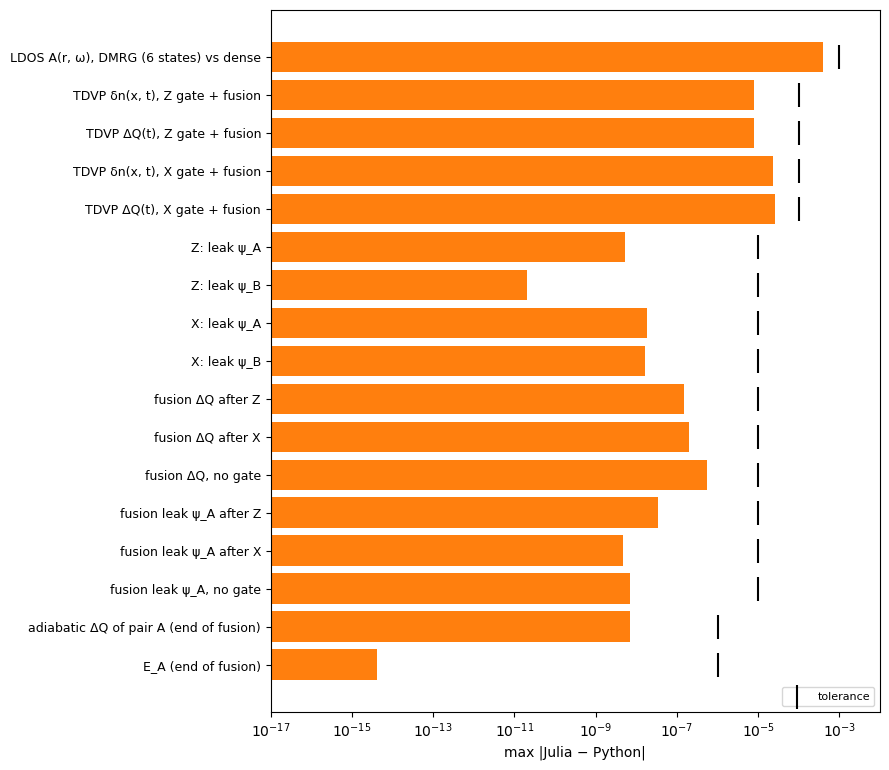

In [6]:
ok = sum(d <= tol for _, d, tol in rows)
print(f"{ok} of {len(rows)} comparisons within tolerance")
for name, d, tol in rows:
    if d > tol:
        print(f"  ✗ {name}: {d:.1e} > {tol:.0e}")

fig, ax = plt.subplots(figsize=(9, 0.4 * len(rows) + 1))
yy = np.arange(len(rows))[::-1]
ax.barh(yy, [max(d, 1e-17) for _, d, _ in rows], color="tab:orange")
ax.scatter([tol for *_, tol in rows], yy, marker="|", s=300, color="k", label="tolerance")
ax.set_xscale("log"); ax.set_xlim(1e-17, 1e-2)
ax.set_yticks(yy); ax.set_yticklabels([name for name, _, _ in rows], fontsize=9)
ax.set_xlabel("max |Julia − Python|"); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()